# Google QUEST: learning question and answer quality

Predict 30 annotation dimensions from a question title, question body and answer. This walkthrough examines the complete official training data, keeps repeated questions together during validation, and connects the modeling choices to recorded experiment artifacts.

The historical public benchmark is **0.43155 Spearman**. A local holdout score is a separate measurement; the modern model must be evaluated through an offline Kaggle notebook before a leaderboard comparison is established.

Set `QUEST_DATA_DIR` to the authorized competition files. The locked project environment provides the `quest` package. Full training uses the GPU entry notebook under `notebooks/kaggle/`; data exploration and recorded-result inspection run locally.

## Data and quality targets

The labels describe related but distinct qualities. Each target can take a fractional score in [0, 1]; several can be high for the same example. We therefore use independent sigmoid outputs and binary cross-entropy with the supplied fractional labels, rather than forcing a 30-way class choice.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from quest.data import ANSWER_TARGETS, QUESTION_TARGETS, TARGETS, group_labels, read_data, split_fold

PROJECT = Path.cwd()
while not (PROJECT / "pyproject.toml").exists():
    PROJECT = PROJECT.parent
DATA_DIR = Path(os.environ.get("QUEST_DATA_DIR", PROJECT / "input"))
RUN_DIR = Path(os.environ.get("QUEST_BENCHMARK_DIR", PROJECT / ".local/kaggle-output/quest-run"))
CONFIG = json.loads((PROJECT / "configs/deberta.json").read_text())
frame = read_data(DATA_DIR / "train.csv", labeled=True)
test = read_data(DATA_DIR / "test.csv", labeled=False)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
print({"training_rows": len(frame), "test_rows": len(test), "targets": len(TARGETS),
       "unique_question_bodies": frame.question_body.nunique()})

{'training_rows': 6079, 'test_rows': 476, 'targets': 30, 'unique_question_bodies': 3583}


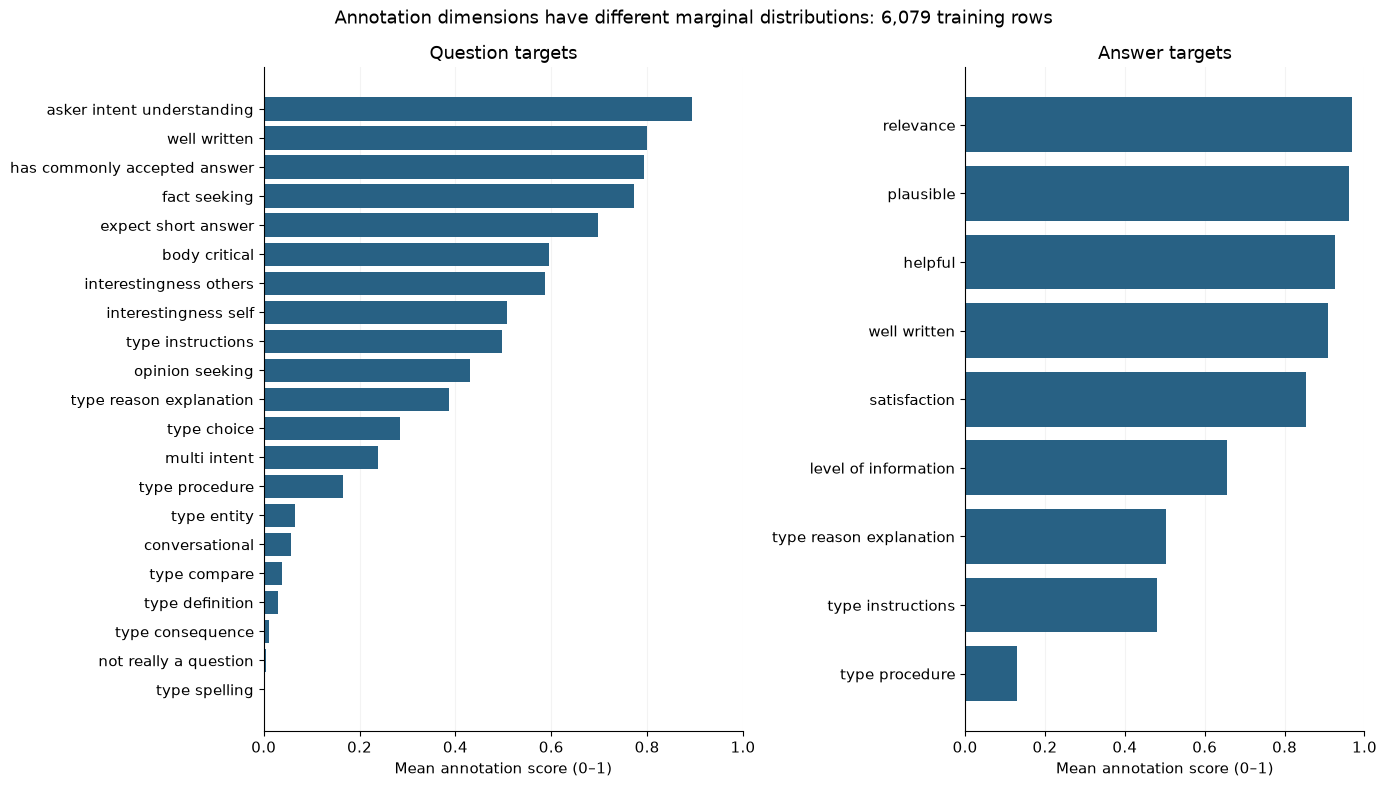

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [1.2, 1]})
for ax, columns, prefix, title in [
    (axes[0], QUESTION_TARGETS, "question_", "Question targets"),
    (axes[1], ANSWER_TARGETS, "answer_", "Answer targets"),
]:
    values = frame[list(columns)].mean().sort_values()
    labels = [name.removeprefix(prefix).replace("_", " ") for name in values.index]
    ax.barh(labels, values, color="#286184")
    ax.set(xlim=(0, 1), xlabel="Mean annotation score (0–1)", title=title)
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)
fig.suptitle(f"Annotation dimensions have different marginal distributions: {len(frame):,} training rows")
fig.tight_layout()
plt.show()

The means describe annotation distributions, not model accuracy. A model could predict a frequent high score for every row yet fail to rank examples correctly. Spearman evaluates the ordering within each target before averaging the 30 correlations. Constant predictions contribute zero in the maintained metric; they are not dropped from the average.

## Repeated questions and validation

Different answers can share one question. An independent row split can expose a validation question during training. GroupKFold keeps these question groups together. The first fold retains the original split convention, so model changes do not silently redefine the holdout.

{'training_rows': 4863, 'validation_rows': 1216, 'shared_question_groups': 0}


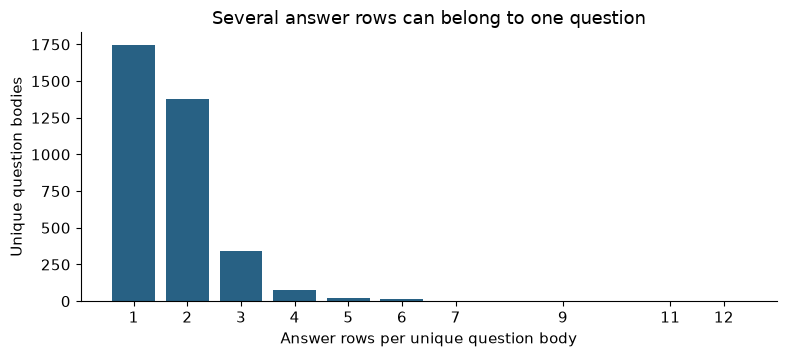

In [3]:
training_indices, validation_indices = split_fold(frame, fold=CONFIG["fold"], folds=CONFIG["folds"])
groups = group_labels(frame)
assert not set(groups.iloc[training_indices]) & set(groups.iloc[validation_indices])
assert not set(frame.question_body.iloc[training_indices]) & set(frame.question_body.iloc[validation_indices])
print({"training_rows": len(training_indices), "validation_rows": len(validation_indices),
       "shared_question_groups": 0})
counts = frame.groupby("question_body", sort=False).size().value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.7))
ax.bar(counts.index, counts.values, color="#286184")
ax.set(title="Several answer rows can belong to one question",
       xlabel="Answer rows per unique question body", ylabel="Unique question bodies")
ax.set_xticks(counts.index)
fig.tight_layout()
plt.show()

Each bar counts question bodies, while the model trains on question–answer rows. That distinction determines the leakage check. This is one grouped holdout, not five-fold out-of-fold evaluation. Further model selection against the same fold can still overfit that validation set.

## Shared transformer and padding-aware pooling

The encoder sees title/body and title/answer pairs separately, sharing its language-model weights. Mean pooling excludes padding positions. The prediction head receives both vectors and their difference, giving it information about each text and their relationship.

```text
title + body   ── shared DeBERTa ── masked mean ── question vector ──┐
title + answer ── shared DeBERTa ── masked mean ── answer vector ────┼─ head → 30 logits
                                                 difference ─────┘
```

[DeBERTa-v3-base](https://huggingface.co/microsoft/deberta-v3-base) replaces the historical BERT/distilRoBERTa presets. AdamW, warmup, cosine decay and gradient clipping use current PyTorch/Transformers APIs. The original code remains in `legacy/`; matching its score would establish a modern replacement's performance, not numerical equality with its TensorFlow graph.

In [4]:
print(json.dumps(CONFIG, indent=2))

{
  "name": "deberta-v3-base-question-group",
  "model": "microsoft/deberta-v3-base",
  "model_revision": "8ccc9b6f36199bec6961081d44eb72fb3f7353f3",
  "head_width": 768,
  "question_length": 384,
  "answer_length": 512,
  "fold": 0,
  "folds": 5,
  "head_epochs": 1,
  "epochs": 5,
  "batch_size": 4,
  "gradient_accumulation_steps": 2,
  "head_learning_rate": 0.001,
  "learning_rate": 2e-05,
  "weight_decay": 0.01,
  "warmup_fraction": 0.1,
  "max_gradient_norm": 1.0,
  "patience": 2,
  "seed": 42,
  "threads": 8,
  "mixed_precision": true,
  "device": "auto"
}


Question and answer token budgets are explicit experimental choices. Gradient accumulation defines the effective batch size; the physical batch remains constrained by GPU memory. The best checkpoint maximizes grouped validation Spearman. Early stopping, token limits and the selected fold must remain visible when comparing results.

## Recorded training and validation

A completed run contains its input and source hashes, resolved configuration, split roles, training history, per-target scores, tokenizer, checkpoint and predictions. Set `QUEST_BENCHMARK_DIR` to that retrieved run directory. Training is launched through `quest train` or the GPU notebook, so inspecting a finished experiment does not silently retrain it.

In [5]:
if (RUN_DIR / "manifest.json").exists():
    manifest = json.loads((RUN_DIR / "manifest.json").read_text())
    assert manifest["status"] == "completed", "Select a completed experiment"
    metrics = json.loads((RUN_DIR / "metrics.json").read_text())
    history = pd.read_json(RUN_DIR / "history.json")
    print({"logical_run_id": manifest["logical_run_id"],
           "grouped_holdout_spearman": metrics["mean_spearman"],
           "training_rows": manifest["train_rows"], "validation_rows": manifest["validation_rows"],
           "source": manifest["source"]})
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(np.arange(1, len(history) + 1), history.validation_spearman, marker="o", color="#286184")
    ax.set(title="Checkpoint selection on the question-group holdout",
           xlabel="Completed training epoch (including head warmup)", ylabel="Mean target Spearman")
    ax.set_xticks(np.arange(1, len(history) + 1))
    fig.tight_layout()
    plt.show()
else:
    print("No completed benchmark selected. GPU training is in progress; no modern score is claimed.")

No completed benchmark selected. GPU training is in progress; no modern score is claimed.


The held-out score measures ranking over this fold's rows. It should not be presented as the historical public leaderboard value. A useful next experiment changes one factor while retaining the split, then checks whether the finding survives additional folds.

## Checkpoint reuse and offline Kaggle inference

The run saves its encoder configuration, complete state and tokenizer, allowing inference without downloading the pretrained model again. `quest evaluate` checks the exact training-file hash and saved holdout indices. `quest predict` validates test IDs and writes all target columns in the official order.

QUEST is a notebook-only competition. The offline inference entry verifies run artifact hashes, predicts the competition-mounted test rows and writes `submission.csv`; the scoring request must identify its notebook version. Local public-test predictions alone do not establish a leaderboard score.

An optional MLflow import can connect a completed local or retrieved Kaggle run to an existing tracker. Training retains its evidence before any service connection. Shared infrastructure is managed separately.

See [architecture](../docs/architecture.md), [reproduction](../docs/reproduction.md) and [measured results](../docs/results.md).